# 02 — Exploratory Data Analysis (EDA)
## Airbnb Buenos Aires — Price Prediction

### Objetivo del notebook
Explorar la calidad, distribución y relaciones de los datos para preparar la selección de variables del modelo de regresión.

**Variable objetivo (`target`):** `price_quote_price_per_night`, el precio por noche de una cotización.

El análisis exploratorio sirve para entender los datos y fundamentar decisiones. En este notebook se identifican posibles problemas y se documentan criterios; el tratamiento definitivo de valores faltantes, codificación y escalado se implementará en `03_data_preprocessing.ipynb`.

### Criterios generales
- Conservar una copia de los datos originales.
- No eliminar valores extremos solo por ser altos: primero investigar si son errores o valores legítimos.
- Evitar fuga de información (*data leakage*): las variables predictoras no deben contener el precio objetivo ni información calculada directamente a partir de él.
- Las decisiones de exclusión son iniciales y deben revisarse según el escenario de uso del modelo.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_original = pd.read_csv("../data/raw/airbnb-buenos-aires.csv")
df = df_original.copy()

print("Dimensiones iniciales:", df.shape)
display(df.head())

Dimensiones iniciales: (29753, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,11508,https://www.airbnb.com/rooms/11508,20260923225042,2026-09-27,NaN,Amazing Luxurious Apt-Palermo Soho,LUXURIOUS 1 BDRM APT- POOL/ GYM/ 24-HR SECURIT...,NaN,https://a0.muscache.com/pictures/19357696/b1de...,42762,...,4.98,4.92,4.82,NaN,NaN,1,1,0,0,0.30
1,13851,https://www.airbnb.com/rooms/13851,20260923225042,2026-09-26,NaN,Excelente ubicación 2amb grandes Balcon propio,The apartment is very nice and in a great loca...,NaN,https://a0.muscache.com/pictures/101816/5e8182...,54220,...,5.00,5.00,3.00,NaN,NaN,1,1,0,0,0.05
2,20062,https://www.airbnb.com/rooms/20062,20260923225042,2026-09-26,NaN,PENTHOUSE /Terrace & pool /City views /2bedrooms,NaN,NaN,https://a0.muscache.com/pictures/165681/b448fd...,75891,...,4.94,4.94,4.82,NaN,NaN,4,4,0,0,1.98
3,24713,https://www.airbnb.com/rooms/24713,20260923225042,2026-09-27,NaN,"Teatro Gran Rex, Tribunales, Obelisco, Subte ...",Beautiful 6th floor apart in the heart of the ...,NaN,https://a0.muscache.com/pictures/0efe9841-2777...,100743,...,4.90,4.84,4.64,NaN,NaN,10,10,0,0,2.39
4,24763,https://www.airbnb.com/rooms/24763,20260923225042,2026-09-26,NaN,Amazing LOFTpalermo: contemporary and cool,Amazing contemporary loft decorated looking at...,NaN,https://a0.muscache.com/pictures/18067542/0d4c...,101049,...,4.81,4.56,4.53,NaN,NaN,1,1,0,0,0.20


## 1. Inspección inicial

Se carga el dataset y se conserva `df_original` sin modificaciones. La variable `df` será la copia de trabajo.

Antes de eliminar columnas, es importante conocer las dimensiones, los tipos de datos y la estructura general del conjunto.

In [27]:
print("Filas y columnas:", df.shape)
display(df.info())

Filas y columnas: (29753, 90)
<class 'pandas.DataFrame'>
RangeIndex: 29753 entries, 0 to 29752
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29753 non-null  int64  
 1   listing_url                                   29753 non-null  str    
 2   scrape_id                                     29753 non-null  int64  
 3   last_scraped                                  29753 non-null  str    
 4   source                                        2113 non-null   str    
 5   name                                          29753 non-null  str    
 6   description                                   29646 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29752 non-null  str    
 9   host_id                                   

None

## 2. Identificar columnas constantes

Una columna constante tiene el mismo valor en todas las filas (incluidos los valores nulos como una categoría). No permite distinguir entre anuncios y, por sí sola, no aporta información al modelo.

Se detectan primero y se eliminan de la copia de trabajo.

In [28]:
constant_columns = [col for col in df.columns if df[col].nunique(dropna=False) <= 1]

print("Columnas constantes:", constant_columns)
df = df.drop(columns=constant_columns)
print("Dimensiones después de eliminar constantes:", df.shape)

Columnas constantes: ['scrape_id', 'neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'instant_bookable']
Dimensiones después de eliminar constantes: (29753, 75)


## 3. Revisar valores faltantes por columna

Se calcula el porcentaje de valores faltantes. Las columnas con más del 50 % de nulos se marcan para una revisión especial, pero el umbral no implica que deban eliminarse automáticamente: una variable importante puede merecer conservarse y tratarse en el preprocesamiento.

La tabla muestra **todas las columnas con nulos** en este punto del análisis, tanto numéricas como categóricas.

In [29]:
missing = (
    df.isna()
    .sum()
    .to_frame(name="cantidad_nulos")
    .assign(porcentaje_nulos=lambda x: (x["cantidad_nulos"] / len(df) * 100).round(2))
    .query("cantidad_nulos > 0")
    .sort_values("porcentaje_nulos", ascending=False)
)

display(missing.style.format({"porcentaje_nulos": "{:.2f}%"}))

,cantidad_nulos,porcentaje_nulos
license,29242,98.28%
source,27640,92.90%
host_about,12927,43.45%
host_location,6595,22.17%
review_scores_checkin,3479,11.69%
review_scores_rating,3479,11.69%
reviews_per_month,3479,11.69%
review_scores_location,3479,11.69%
review_scores_cleanliness,3479,11.69%
review_scores_communication,3479,11.69%


In [30]:
missing_percentage = df.isna().mean() * 100
columns_over_50_missing = missing_percentage[missing_percentage > 50].sort_values(
    ascending=False
)

print("Columnas con más del 50 % de valores faltantes:")
display(columns_over_50_missing.to_frame("porcentaje_nulos"))

Columnas con más del 50 % de valores faltantes:


,porcentaje_nulos
license,98.282526
source,92.898195


### Criterio para columnas con muchos nulos

Una proporción elevada de valores faltantes puede dificultar el uso de una variable. Sin embargo, antes de excluirla hay que considerar su significado y su posible utilidad predictiva. En esta selección inicial se eliminan las columnas que superan el umbral del 50 %, dejando registrada la regla aplicada.

In [31]:
df = df.drop(columns=columns_over_50_missing.index)
print("Dimensiones después del filtro de nulos:", df.shape)

Dimensiones después del filtro de nulos: (29753, 73)


## 4. Identificar columnas que funcionan como identificadores

Las columnas cuyos valores son únicos para cada fila pueden funcionar como identificadores (por ejemplo, IDs o URLs). Generalmente no se usan directamente como predictores porque identifican el registro, en vez de describir una característica generalizable del alojamiento.

**Precaución:** tener muchos valores únicos no significa automáticamente que una variable sea inútil. Los nombres, descripciones y ubicaciones pueden contener información, pero requieren un tratamiento específico. La decisión depende del alcance del modelo.

In [32]:
identifier_like_columns = [
    col for col in df.columns if df[col].nunique(dropna=False) == len(df)
]

print("Columnas con un valor único por fila:")
print(identifier_like_columns)

Columnas con un valor único por fila:
['id', 'listing_url']


In [33]:
df = df.drop(columns=identifier_like_columns)
print("Dimensiones después de retirar identificadores:", df.shape)

Dimensiones después de retirar identificadores: (29753, 71)


## 5. Identificar columnas duplicadas

Si dos columnas contienen exactamente los mismos valores en todas las filas, mantener ambas duplica información sin aportar una señal adicional. Se detectan y se retiran las columnas duplicadas.

In [34]:
duplicate_columns = df.columns[df.T.duplicated()].tolist()
print("Columnas duplicadas:", duplicate_columns)

Columnas duplicadas: ['minimum_minimum_nights', 'maximum_maximum_nights', 'calendar_last_scraped']


In [35]:
df = df.drop(columns=duplicate_columns)
print("Dimensiones después de retirar duplicadas:", df.shape)

Dimensiones después de retirar duplicadas: (29753, 68)


## 6. Selección manual de variables: criterios y justificación

La siguiente lista corresponde a una **selección inicial**. La justificación se agrupa por tipo de variable; no se asume que todas las columnas excluidas carezcan de valor predictivo.

### Identificadores, enlaces y contenido no estructurado
- `name`, `description`, `host_about`: textos libres que podrían aportar información, pero requieren técnicas de procesamiento de texto (NLP), fuera del alcance del primer modelo.
- `picture_url`, `host_picture_url`: enlaces a imágenes; la URL no representa por sí misma características visuales. Analizar las imágenes requeriría un flujo distinto.
- `host_id`, `host_profile_id`, `host_url`, `host_profile_url`, `host_name`: identificadores, enlaces o nombres del anfitrión; no se usarán como predictores directos en el modelo inicial.
- `host_location`, `host_has_profile_pic`: se excluyen del primer modelo por alcance, aunque podrían evaluarse en iteraciones futuras.

### Variables de tiempo, actividad, disponibilidad y reseñas
- `last_scraped`: fecha de extracción, asociada al proceso de recopilación.
- `first_review`, `last_review`, `reviews_per_month`, `number_of_reviews_ltm`, `number_of_reviews_l30d`, `number_of_reviews_ly`: describen actividad y antigüedad del anuncio. Se excluyen en esta versión por alcance; podrían aportar señal y deben reconsiderarse en una iteración posterior.
- `availability_30`, `availability_60`, `availability_90`, `availability_eoy`, `has_availability`: disponibilidad que puede depender de la fecha de consulta y del comportamiento de reservas. Se excluye en esta versión inicial; su utilidad depende del momento en que se hará la predicción.
- `estimated_revenue_l365d`, `estimated_occupancy_l365d`: variables calculadas a partir de ingresos u ocupación. Pueden revelar indirectamente información vinculada al precio o a resultados posteriores, por lo que se excluyen para reducir el riesgo de fuga de información.
- `calculated_host_listings_count`, `calculated_host_listings_count_shared_rooms`, `calculated_host_listings_count_private_rooms`, `calculated_host_listings_count_entire_homes`, `host_listings_count`: describen la cantidad de anuncios asociados al anfitrión. Se excluyen del modelo inicial por alcance, aunque podrían ser útiles y conviene evaluar su aporte posteriormente.
- `hosts_time_as_user_years`, `hosts_time_as_user_months`, `hosts_time_as_host_years`, `hosts_time_as_host_months`: describen antigüedad del anfitrión en la plataforma. Se excluyen en esta primera versión, pero podrían aportar información indirecta.

### Variables de cotización y riesgo de fuga de información
- `price_quote_total_price`: precio total de una cotización; está directamente relacionado con el precio por noche y la duración de la estadía, por lo que no se utilizará como predictor.
- `price_quote_raw`: campo crudo de la cotización que puede contener el propio precio u otros datos redundantes; se excluye.
- `price`: se excluye como predictor porque es otra variable de precio del anuncio y podría filtrar información muy cercana al objetivo. No se utilizará para predecir `price_quote_price_per_night`.
- `price_quote_checkin_date` y `price_quote_checkout_date`: se mantienen fuera del primer modelo por decisión de alcance. **Podrían ser útiles** para capturar temporada y duración; si el escenario de predicción dispone de esas fechas antes de cotizar, conviene reconsiderarlas y crear variables como mes, día de la semana o cantidad de noches.

### Variables de restricciones y puntuaciones
- `maximum_minimum_nights`, `minimum_maximum_nights`, `minimum_nights_avg_ntm`, `maximum_nights_avg_ntm`: variables relacionadas con restricciones o promedios de noches; se excluyen en esta versión por alcance y podrían reevaluarse.
- `review_scores_accuracy`, `review_scores_cleanliness`, `review_scores_checkin`, `review_scores_communication`, `review_scores_location`, `review_scores_value`: puntuaciones de reseñas. Se excluyen en el modelo inicial, pero podrían tener valor predictivo. Además, podrían no existir para anuncios nuevos; la decisión debe corresponder al escenario de uso.
- `host_identity_verified`: indica si el anfitrión verificó su identidad. Se excluye por alcance, aunque podría evaluarse posteriormente.

**Importante:** la lista no incluye el target `price_quote_price_per_night`. Esta columna debe conservarse como variable objetivo y no incorporarse a `X` (las variables predictoras).

In [36]:
to_drop_columns = [
    "last_scraped",
    "name",
    "description",
    "picture_url",
    "host_id",
    "host_url",
    "host_profile_id",
    "host_profile_url",
    "host_name",
    "hosts_time_as_user_years",
    "hosts_time_as_user_months",
    "hosts_time_as_host_years",
    "hosts_time_as_host_months",
    "host_location",
    "host_about",
    "host_picture_url",
    "host_has_profile_pic",
    "price_quote_checkin_date",
    "price_quote_checkout_date",
    "price_quote_total_price",
    "price",
    "price_quote_raw",
    "maximum_minimum_nights",
    "minimum_maximum_nights",
    "minimum_nights_avg_ntm",
    "maximum_nights_avg_ntm",
    "has_availability",
    "availability_30",
    "availability_60",
    "availability_90",
    "number_of_reviews_ltm",
    "number_of_reviews_l30d",
    "availability_eoy",
    "number_of_reviews_ly",
    "estimated_revenue_l365d",
    "first_review",
    "last_review",
    "reviews_per_month",
    "calculated_host_listings_count_shared_rooms",
    "calculated_host_listings_count_private_rooms",
    "calculated_host_listings_count_entire_homes",
    "calculated_host_listings_count",
    "host_listings_count",
    "host_identity_verified",
    "review_scores_accuracy",
    "review_scores_cleanliness",
    "review_scores_checkin",
    "review_scores_communication",
    "review_scores_location",
    "review_scores_value",
    "estimated_occupancy_l365d",
]

# Solo se intentan eliminar columnas que estén presentes en este dataset.
manual_columns_present = [col for col in to_drop_columns if col in df.columns]
manual_columns_missing = [col for col in to_drop_columns if col not in df.columns]

print("Columnas que se eliminarán:", len(manual_columns_present))
print("Columnas de la lista que no están presentes:", manual_columns_missing)

df = df.drop(columns=manual_columns_present)
print("Dimensiones después de la selección inicial:", df.shape)

Columnas que se eliminarán: 51
Columnas de la lista que no están presentes: []
Dimensiones después de la selección inicial: (29753, 17)


## 7. Confirmar la variable objetivo

La variable que se busca predecir es `price_quote_price_per_night` (precio por noche de la cotización). Se verifica que exista y se inspeccionan su tipo de dato, valores faltantes y algunos registros.

Antes del entrenamiento habrá que confirmar que el precio esté en un formato numérico. Si está guardado como texto con símbolos monetarios o separadores, la conversión se documentará en el notebook 03.

In [37]:
target = "price_quote_price_per_night"

if target not in df.columns:
    raise KeyError(f"No se encontró la variable objetivo: {target}")

print("Tipo de dato:", df[target].dtype)
print("Valores faltantes:", df[target].isna().sum())
display(df[target].head(10))
display(df[target].describe())

Tipo de dato: float64
Valores faltantes: 2120


0    186530.00
1     91729.00
2    232074.07
3    117408.00
4    465014.50
5    120012.00
6    162272.86
7    182973.00
8     59957.40
9    144473.00
Name: price_quote_price_per_night, dtype: float64

count    2.763300e+04
mean     2.777709e+05
std      3.545239e+06
min      2.465900e+02
25%      7.949850e+04
50%      1.063930e+05
75%      1.486772e+05
max      1.605638e+08
Name: price_quote_price_per_night, dtype: float64

### Distribución del precio objetivo

El histograma permite observar asimetría y concentración de precios. El boxplot ayuda a identificar observaciones extremas. Los puntos extremos no se eliminan automáticamente: primero se investigará si son errores o precios válidos.

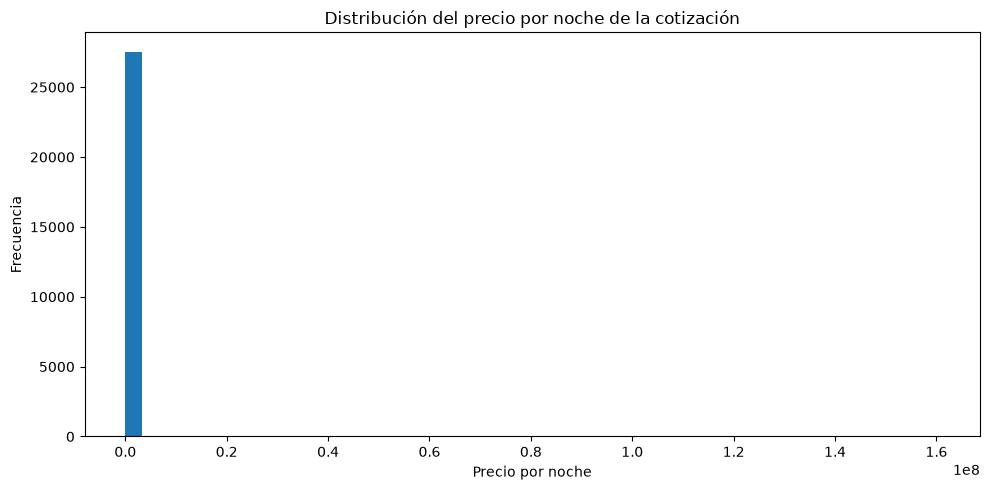

In [38]:
target_values = pd.to_numeric(df[target], errors="coerce")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(target_values.dropna(), bins=50)
ax.set_title("Distribución del precio por noche de la cotización")
ax.set_xlabel("Precio por noche")
ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

In [39]:
price = df[target]
Q1 = price.quantile(0.25)
Q3 = price.quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = price[(price < limite_inferior) | (price > limite_superior)]

print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)
print("Cantidad de outliers:", outliers.count())
print(
    "Porcentaje de outliers:",
    round(outliers.count() / price.notna().sum() * 100, 2),
    "%",
)

Límite inferior: -24269.625
Límite superior: 252445.375
Cantidad de outliers: 2160
Porcentaje de outliers: 7.82 %


In [40]:
# Cantidad de precios negativos o iguales a cero
print("Precios <= 0:", (price <= 0).sum())

# Cantidad de precios por encima del límite superior
print("Precios por encima del límite:", (price > limite_superior).sum())

# Los 20 precios más altos
display(price[price > limite_superior].sort_values(ascending=False).head(20))

price.quantile([0.90, 0.95, 0.99, 0.995, 0.999])

Precios <= 0: 0
Precios por encima del límite: 2160


28911    1.605638e+08
14179    1.528815e+08
10200    1.376224e+08
16837    1.320896e+08
4449     1.213573e+08
6653     1.146624e+08
26598    1.101320e+08
26595    1.101052e+08
23147    1.070874e+08
24268    1.070170e+08
16836    1.027363e+08
16854    9.845566e+07
16852    9.845566e+07
16855    9.845566e+07
16869    9.819503e+07
16870    9.704915e+07
16848    9.539803e+07
6756     9.173652e+07
16868    9.142312e+07
16856    9.142312e+07
Name: price_quote_price_per_night, dtype: float64

0.900    2.262646e+05
0.950    3.154417e+05
0.990    8.994938e+05
0.995    1.602482e+06
0.999    7.547452e+07
Name: price_quote_price_per_night, dtype: float64

### Detección de valores atípicos en el precio

Se aplicó el método del rango intercuartílico (IQR) a la variable objetivo `price_quote_price_per_night`. Se obtuvo un límite inferior de -24.269,625 y un límite superior de 252.445,375.

Según este criterio, se identificaron 2.160 observaciones atípicas, equivalentes al 7,82 % de los precios válidos.

La detección mediante IQR no implica que estos registros sean errores. Los valores extremos se investigarán para determinar si corresponden a precios legítimos o a posibles inconsistencias. No se eliminarán automáticamente, ya que hacerlo podría excluir alojamientos válidos y sesgar el modelo.

La decisión final sobre su tratamiento se tomará durante el preprocesamiento y la experimentación con modelos.

C:\Users\Matias Montenegro\AppData\Local\Temp\ipykernel_22364\4274900425.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(target_values.dropna(), vert=False)


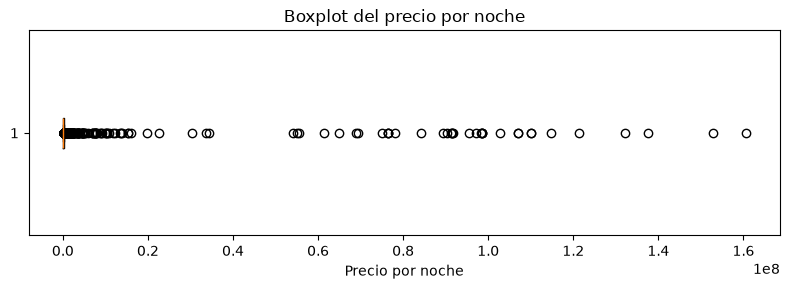

In [41]:
plt.figure(figsize=(8, 3))
plt.boxplot(target_values.dropna(), vert=False)
plt.title("Boxplot del precio por noche")
plt.xlabel("Precio por noche")
plt.tight_layout()
plt.show()

In [42]:
print("15 valores más altos del target:")
display(target_values.sort_values(ascending=False).head(15))

print("Percentiles del target:")
display(target_values.describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.999]))

15 valores más altos del target:


28911    1.605638e+08
14179    1.528815e+08
10200    1.376224e+08
16837    1.320896e+08
4449     1.213573e+08
6653     1.146624e+08
26598    1.101320e+08
26595    1.101052e+08
23147    1.070874e+08
24268    1.070170e+08
16836    1.027363e+08
16852    9.845566e+07
16855    9.845566e+07
16854    9.845566e+07
16869    9.819503e+07
Name: price_quote_price_per_night, dtype: float64

Percentiles del target:


count    2.763300e+04
mean     2.777709e+05
std      3.545239e+06
min      2.465900e+02
50%      1.063930e+05
75%      1.486772e+05
90%      2.262646e+05
95%      3.154417e+05
99%      8.994938e+05
99.9%    7.547452e+07
max      1.605638e+08
Name: price_quote_price_per_night, dtype: float64

### Vista complementaria: distribución hasta el percentil 99

Este gráfico se utiliza únicamente para observar mejor la mayor parte de los precios sin que los valores extremos compriman el histograma. **No implica eliminar el 1 % superior** ni define todavía una regla de tratamiento de outliers.

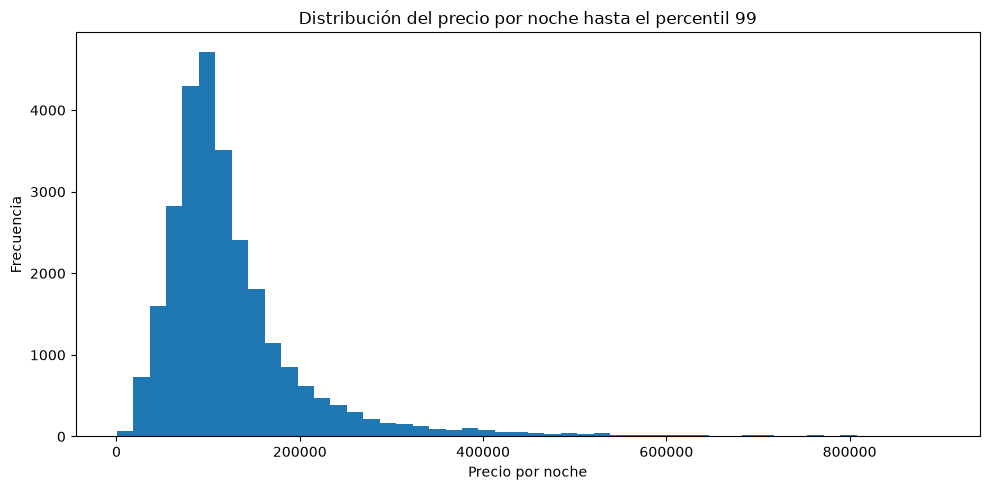

In [43]:
p99 = target_values.quantile(0.99)

target_values[target_values <= p99].dropna().plot(kind="hist", bins=50, figsize=(10, 5))
plt.title("Distribución del precio por noche hasta el percentil 99")
plt.xlabel("Precio por noche")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

In [ ]:
# Eliminar filas outliers del percentil 99 con drop
df.drop(df[df[target] > p99].index, inplace=True)

## 8. Distribución de variables numéricas

Se revisan estadísticas descriptivas y distribuciones para detectar escalas distintas, asimetrías, valores improbables y posibles outliers. Estos gráficos son diagnósticos; no justifican por sí solos eliminar registros.

In [45]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()
display(df[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
latitude,29476.0,-34.592167,0.017979,-34.68388,-34.603417,-34.591570,-34.581440,-34.53498
longitude,29476.0,-58.416147,0.030169,-58.53089,-58.435970,-58.418235,-58.390454,-58.35553
accommodates,29476.0,2.912641,1.501439,1.00000,2.000000,2.000000,4.000000,16.00000
bedrooms,29463.0,1.139293,0.882253,0.00000,1.000000,1.000000,1.000000,31.00000
beds,28960.0,1.912189,1.453822,1.00000,1.000000,1.000000,2.000000,50.00000
price_quote_price_per_night,27356.0,128808.463766,92373.522725,246.59000,79192.600000,105585.165000,146766.500000,897415.00000
minimum_nights,29475.0,4.911722,18.627348,1.00000,1.000000,2.000000,3.000000,730.00000
maximum_nights,29475.0,547.855539,426.991601,1.00000,300.000000,365.000000,1125.000000,3659.00000
availability_365,29476.0,234.433980,115.566010,0.00000,145.000000,268.000000,339.000000,365.00000
number_of_reviews,29476.0,41.910232,61.695989,0.00000,4.000000,18.000000,55.000000,1155.00000


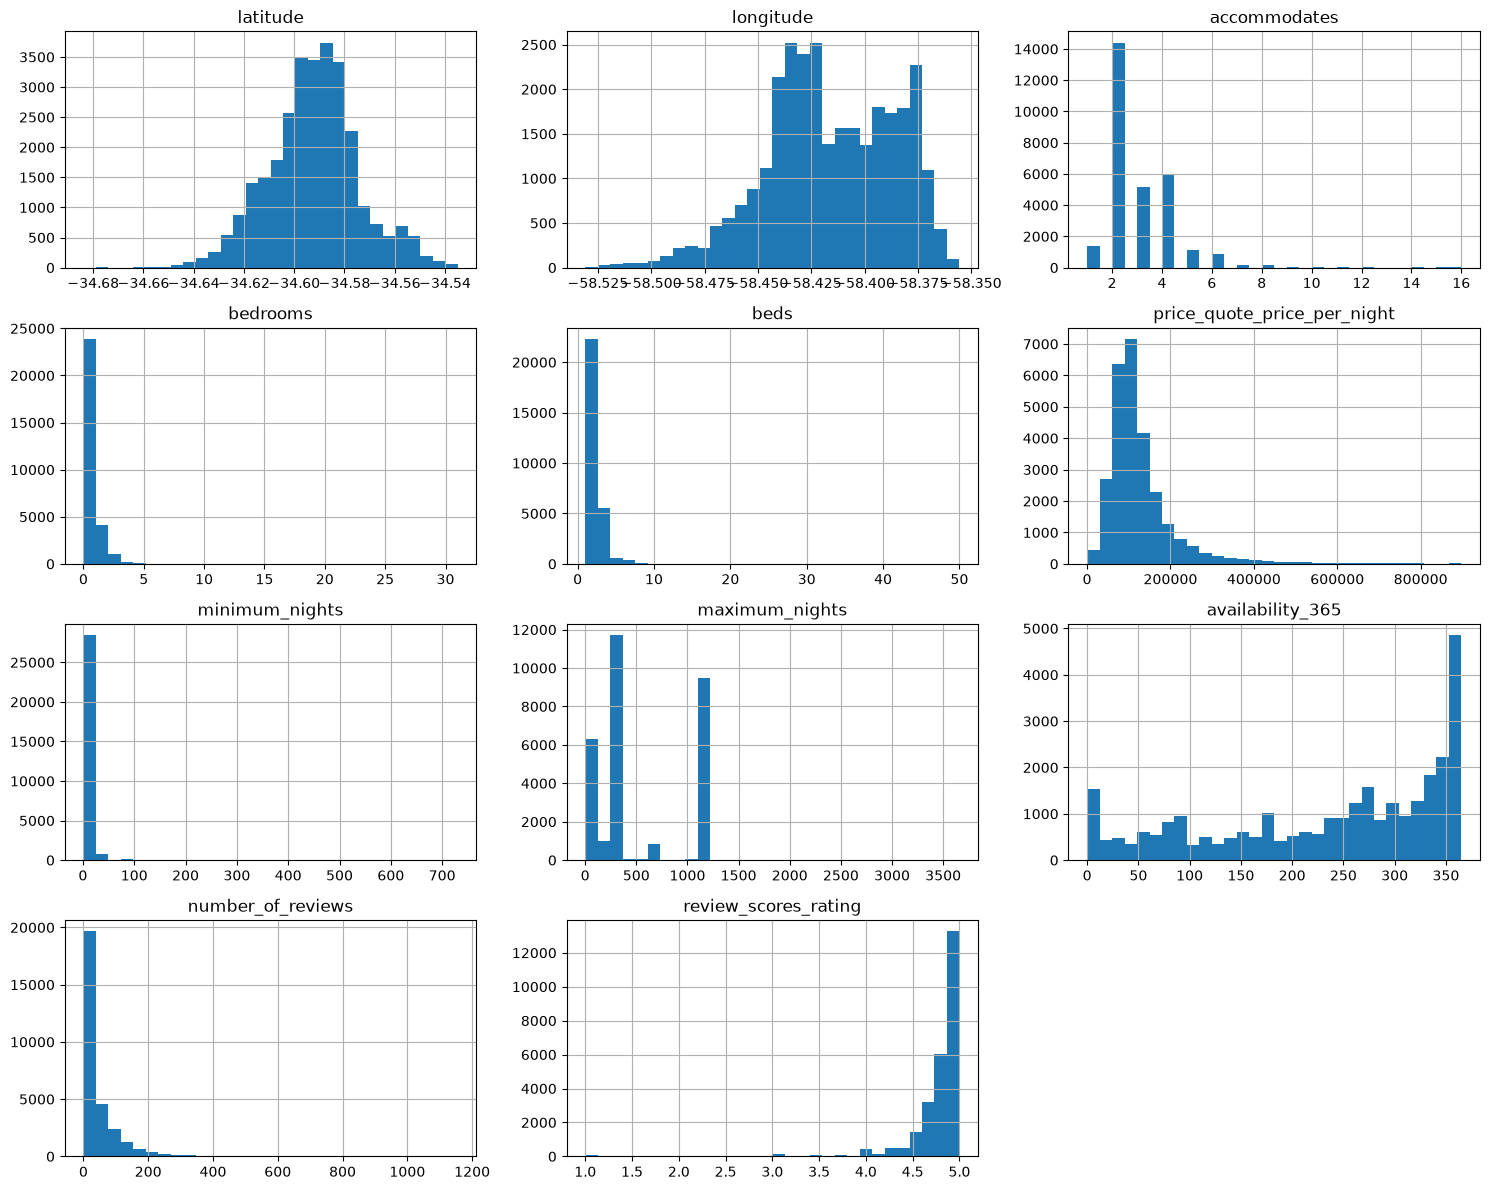

In [46]:
if numeric_columns:
    df[numeric_columns].hist(figsize=(15, 12), bins=30)
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron columnas numéricas para graficar.")

## 9. Distribución de variables categóricas

Se muestran las categorías más frecuentes de cada variable categórica. Esto permite detectar valores inconsistentes, categorías poco frecuentes y columnas con cardinalidad elevada antes de decidir cómo codificarlas en el preprocesamiento.

In [47]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

for col in categorical_columns:
    print(f"\n--- {col} ---")
    display(df[col].value_counts(dropna=False).head(15).to_frame("frecuencia"))


--- host_is_superhost ---


C:\Users\Matias Montenegro\AppData\Local\Temp\ipykernel_22364\873759310.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


,frecuencia
host_is_superhost,
f,17215
t,12261



--- neighbourhood_cleansed ---


,frecuencia
neighbourhood_cleansed,
Palermo,9590
Recoleta,4055
San Nicolas,2402
Retiro,1465
Monserrat,1446
Belgrano,1428
Balvanera,1173
Almagro,1080
Villa Crespo,1011


...

,frecuencia
room_type,
Entire home/apt,26627
Private room,2555
Shared room,164
Hotel room,130



--- bathrooms_text ---


,frecuencia
bathrooms_text,
1 bath,21288
1.5 baths,2730
2 baths,1965
1 private bath,897
1 shared bath,738
2.5 baths,429
3 baths,278
2 shared baths,202
1.5 shared baths,188



--- amenities ---


,frecuencia
amenities,
"[""Kitchen"", ""TV"", ""Wifi"", ""Air conditioning""]",123
"[""Air conditioning"", ""TV"", ""Washer"", ""Kitchen"", ""Wifi""]",79
"[""Dedicated workspace"", ""Air conditioning"", ""TV"", ""Washer"", ""Kitchen"", ""Wifi""]",65
"[""Dedicated workspace"", ""Air conditioning"", ""TV"", ""Kitchen"", ""Wifi""]",44
"[""Air conditioning"", ""TV"", ""Exterior security cameras on property"", ""Kitchen"", ""Wifi""]",32
"[""Kitchen"", ""TV"", ""Wifi""]",24
"[""Air conditioning"", ""TV"", ""Host greets you"", ""Kitchen"", ""Wifi""]",20
"[""Air conditioning"", ""TV"", ""Pets allowed"", ""Kitchen"", ""Wifi""]",18
"[""Dedicated workspace"", ""Air conditioning"", ""TV"", ""Exterior security cameras on property"", ""Kitchen"", ""Wifi""]",17


## 10. Relación entre variables numéricas y el target

La correlación de Pearson mide asociación lineal entre variables numéricas. No detecta necesariamente relaciones no lineales y no demuestra causalidad.

Se crea una copia de análisis y se añade una versión numérica del target solo para estos cálculos. Las transformaciones definitivas y el manejo de nulos se implementarán en el notebook de preprocesamiento.

In [48]:
df_analysis = df.copy()
df_analysis["_target_numeric"] = pd.to_numeric(df_analysis[target], errors="coerce")

numeric_for_corr = df_analysis.select_dtypes(include="number").columns.tolist()
correlations = (
    df_analysis[numeric_for_corr]
    .corr(numeric_only=True)["_target_numeric"]
    .drop("_target_numeric", errors="ignore")
    .sort_values(ascending=False)
)

display(correlations.to_frame("correlacion_con_target"))

,correlacion_con_target
price_quote_price_per_night,1.000000
accommodates,0.508393
beds,0.382312
bedrooms,0.368921
latitude,0.113731
availability_365,0.070103
review_scores_rating,0.055490
maximum_nights,0.045279
longitude,0.010210
number_of_reviews,-0.001639


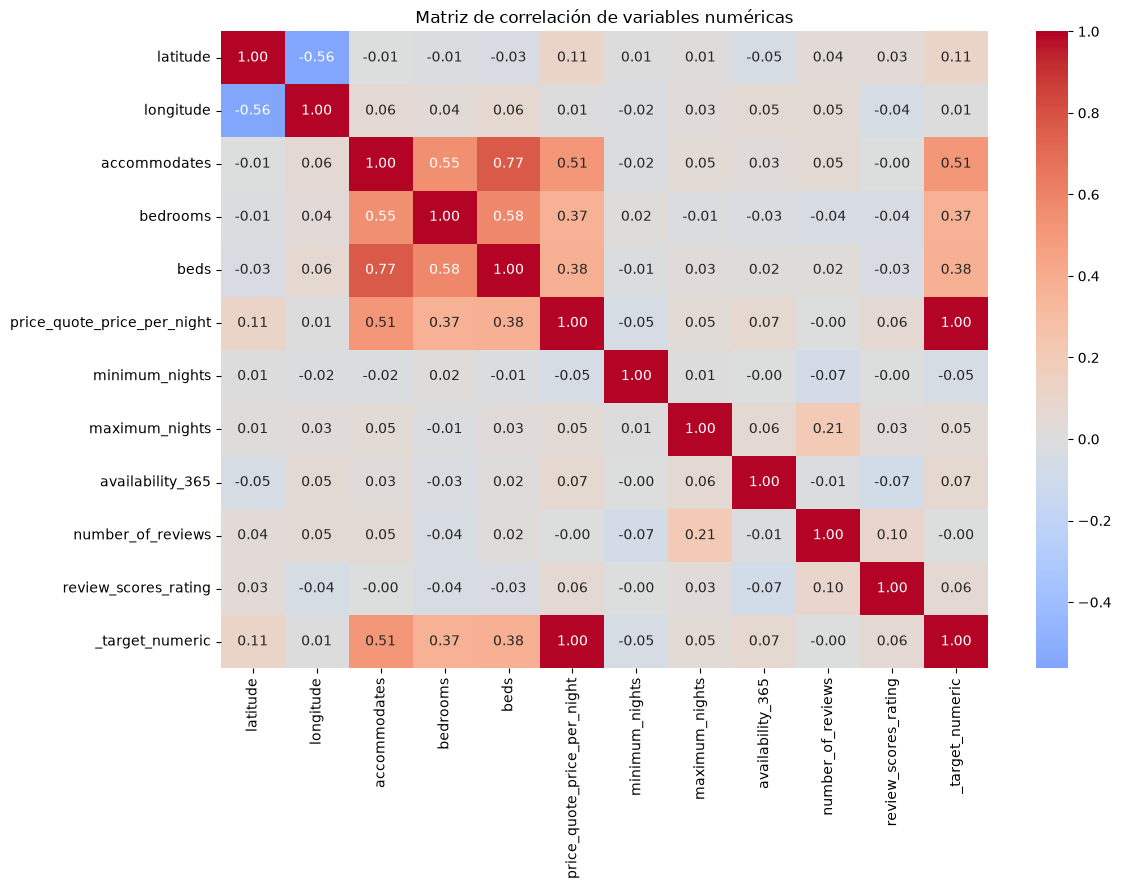

In [49]:
corr_matrix = df_analysis[numeric_for_corr].corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f")

plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

In [50]:
df.to_csv("../data/processed/airbnb_eda.csv", index=False)

## 11. Conclusiones del EDA y decisiones para el notebook 03

Completar estas conclusiones después de ejecutar todas las celdas:

1. **Target:** `price_quote_price_per_night`, precio por noche de la cotización.
2. **Calidad de datos:** resumir las columnas con más valores faltantes y decidir cuáles requieren imputación o eliminación de filas.
3. **Formato del target:** confirmar si necesita conversión a numérico y documentar cualquier limpieza necesaria.
4. **Outliers:** describir los valores extremos observados y verificar si son plausibles antes de decidir cómo tratarlos.
5. **Variables predictoras:** resumir cuáles parecen prometedoras y cuáles se excluyeron por identificadores, texto libre, redundancia o posible fuga de información.
6. **Limitaciones:** las correlaciones no implican causalidad; las relaciones no lineales y el valor de las variables categóricas requieren análisis adicional.

### Próximo paso: `03_data_preprocessing.ipynb`

En el notebook 03 se implementará un flujo reproducible:
- separar variables predictoras (`X`) y objetivo (`y`);
- dividir train/test antes de ajustar imputadores, codificadores o escaladores;
- convertir el target a numérico y tratar filas sin target válido;
- imputar valores faltantes;
- codificar variables categóricas y escalar las numéricas cuando el modelo lo requiera;
- utilizar `Pipeline` y `ColumnTransformer` para prevenir fuga de información.

No se deben ajustar imputadores, codificadores ni escaladores con el conjunto de test.